In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, StratifiedKFold, RepeatedKFold, LeaveOneOut, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
df = pd.read_csv('/mnt/user-data/uploads/train_2.csv')
df = df.drop(columns='id')
df['satisfaction'] = df['satisfaction'].astype(int)
data = df.sample(20000, random_state=42).reset_index(drop=True)
X = data.drop(columns='satisfaction')
y = data['satisfaction']
print(X.shape, y.mean())

(20000, 21) 0.4417


In [3]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
])

In [4]:
model = Pipeline([
    ('prep', preprocess),
    ('rf', RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42))
])

In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

kf_scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
print('K-Fold scores:', np.round(kf_scores, 4))
print(f'Mean = {kf_scores.mean():.4f}, Std = {kf_scores.std():.4f}')

K-Fold scores: [0.913  0.9182 0.9055 0.9138 0.906 ]
Mean = 0.9113, Std = 0.0049


In [6]:
skf_scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
print('Stratified K-Fold scores:', np.round(skf_scores, 4))
print(f'Mean = {skf_scores.mean():.4f}, Std = {skf_scores.std():.4f}')

Stratified K-Fold scores: [0.908  0.9142 0.9038 0.9138 0.9145]
Mean = 0.9108, Std = 0.0043


In [7]:
rkf_scores = cross_val_score(model, X, y, cv=rkf, scoring='accuracy')
print('Number of evaluations:', len(rkf_scores))
print(f'Mean = {rkf_scores.mean():.4f}, Std = {rkf_scores.std():.4f}')

Number of evaluations: 15
Mean = 0.9108, Std = 0.0036


                   Evaluations  Mean Accuracy     Std
K-Fold                       5         0.9113  0.0049
Stratified K-Fold            5         0.9108  0.0043
Repeated K-Fold             15         0.9108  0.0036


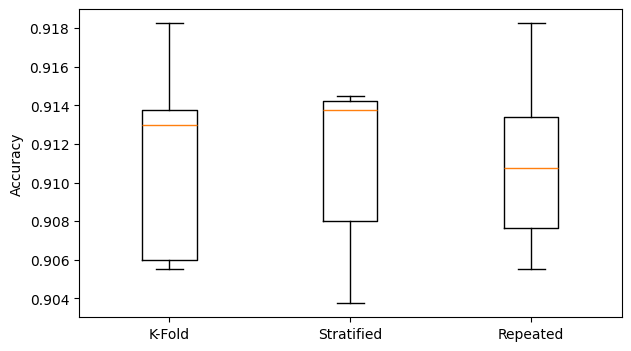

In [8]:
summary = pd.DataFrame({
    'Evaluations': [len(kf_scores), len(skf_scores), len(rkf_scores)],
    'Mean Accuracy': [kf_scores.mean(), skf_scores.mean(), rkf_scores.mean()],
    'Std': [kf_scores.std(), skf_scores.std(), rkf_scores.std()],
}, index=['K-Fold', 'Stratified K-Fold', 'Repeated K-Fold'])
print(summary.round(4))

plt.figure(figsize=(7, 4))
plt.boxplot([kf_scores, skf_scores, rkf_scores], tick_labels=['K-Fold', 'Stratified', 'Repeated'])
plt.ylabel('Accuracy')
plt.show()

In [9]:
print('Stratified K-Fold is generally preferred for classification because it keeps the class proportions')
print('about the same in every fold. Plain K-Fold can produce folds with skewed class ratios, especially with')
print('imbalanced data, which makes fold scores noisier and the estimate less reliable.')
print('Repeated K-Fold averages over several random partitions, giving a more stable estimate at higher cost.')

Stratified K-Fold is generally preferred for classification because it keeps the class proportions
about the same in every fold. Plain K-Fold can produce folds with skewed class ratios, especially with
imbalanced data, which makes fold scores noisier and the estimate less reliable.
Repeated K-Fold averages over several random partitions, giving a more stable estimate at higher cost.


In [10]:
small = data.sample(300, random_state=1)
X_small = small.drop(columns='satisfaction')
y_small = small['satisfaction']

small_model = Pipeline([
    ('prep', ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
    ])),
    ('lr', LogisticRegression(max_iter=1000))
])

loo = LeaveOneOut()
loo_scores = cross_val_score(small_model, X_small, y_small, cv=loo)
print('Number of evaluations:', len(loo_scores))
print('Mean score:', round(loo_scores.mean(), 4))

Number of evaluations: 300
Mean score: 0.8633
